In [1]:
import pandas as pd

In [2]:
df=pd.read_csv('../data/raw/car data.csv')
print(df.head())

  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  


In [ ]:
df['Selling_Price']=df['Selling_Price']*100000
df['Present_Price']=df['Present_Price']*100000
df.head()


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,335000.0,559000.0,27000,Petrol,Dealer,Manual,0
1,sx4,2013,475000.0,954000.0,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,725000.0,985000.0,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,285000.0,415000.0,5200,Petrol,Dealer,Manual,0
4,swift,2014,460000.0,687000.0,42450,Diesel,Dealer,Manual,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       201 non-null    object 
 1   Year           201 non-null    int64  
 2   Selling_Price  201 non-null    float64
 3   Present_Price  201 non-null    float64
 4   Kms_Driven     201 non-null    int64  
 5   Fuel_Type      201 non-null    object 
 6   Seller_Type    201 non-null    object 
 7   Transmission   201 non-null    object 
 8   Owner          201 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 14.3+ KB


In [5]:
# import date and time
from datetime import datetime

# create a function for today date
todays_date = datetime.now()
print("Today's date:", todays_date)

Today's date: 2025-09-14 17:16:57.236052


In [6]:
df['car_age'] = todays_date.year - df['Year']
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,car_age
0,ritz,2014,335000.0,559000.0,27000,Petrol,Dealer,Manual,0,11
1,sx4,2013,475000.0,954000.0,43000,Diesel,Dealer,Manual,0,12
2,ciaz,2017,725000.0,985000.0,6900,Petrol,Dealer,Manual,0,8
3,wagon r,2011,285000.0,415000.0,5200,Petrol,Dealer,Manual,0,14
4,swift,2014,460000.0,687000.0,42450,Diesel,Dealer,Manual,0,11


In [9]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       201 non-null    object 
 1   Year           201 non-null    int64  
 2   Selling_Price  201 non-null    float64
 3   Present_Price  201 non-null    float64
 4   Kms_Driven     201 non-null    int64  
 5   Fuel_Type      201 non-null    object 
 6   Seller_Type    201 non-null    object 
 7   Transmission   201 non-null    object 
 8   Owner          201 non-null    int64  
 9   car_age        201 non-null    int64  
dtypes: float64(2), int64(4), object(4)
memory usage: 15.8+ KB
None


In [18]:
df.corr(numeric_only=True)

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,car_age
Year,1.000000,0.346141,-0.060279,-0.705477,-0.152243,-1.000000
Selling_Price,0.346141,1.000000,0.826635,-0.101332,-0.083620,-0.346141
Present_Price,-0.060279,0.826635,1.000000,0.253505,0.047002,0.060279
Kms_Driven,-0.705477,-0.101332,0.253505,1.000000,0.197756,0.705477
Owner,-0.152243,-0.083620,0.047002,0.197756,1.000000,0.152243
car_age,-1.000000,-0.346141,0.060279,0.705477,0.152243,1.000000


<Axes: >

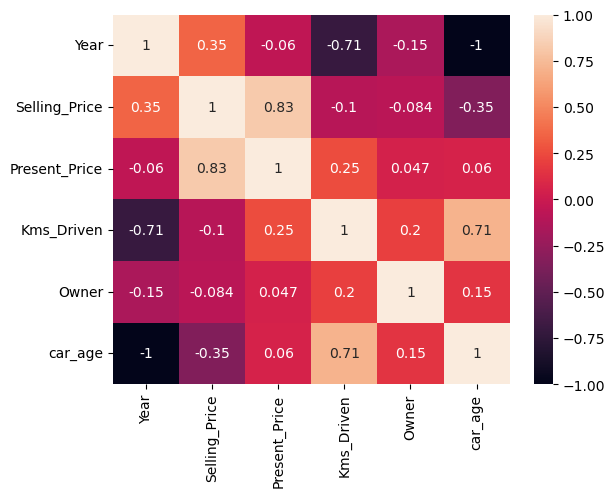

In [19]:
import seaborn as sns
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [21]:
df=pd.get_dummies(df.drop(['Car_Name','Seller_Type'],axis=1),dtype=int)
df.head()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,car_age,Fuel_Type_CNG,Fuel_Type_Diesel,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual
0,2014,335000.0,559000.0,27000,0,11,0,0,1,0,1
1,2013,475000.0,954000.0,43000,0,12,0,1,0,0,1
2,2017,725000.0,985000.0,6900,0,8,0,0,1,0,1
3,2011,285000.0,415000.0,5200,0,14,0,0,1,0,1
4,2014,460000.0,687000.0,42450,0,11,0,1,0,0,1


In [22]:
df.to_csv('../data/procesed/car prosesed.csv')